In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping


In [ ]:
train_dir = "/content/drive/MyDrive/Mendeley_16Class_Dataset/train"
test_dir  = "/content/drive/MyDrive/Mendeley_16Class_Dataset/test"

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)


Found 2560 images belonging to 16 classes.
Found 640 images belonging to 16 classes.


In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
# Freeze all layers first
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze top 25% layers
unfreeze_from = int(len(base_model.layers) * 0.75)

for layer in base_model.layers[unfreeze_from:]:
    layer.trainable = True


In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
output = Dense(16, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)


In [ ]:
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
checkpoint_cb = ModelCheckpoint(
    filepath="/content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

earlystop_cb = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


In [ ]:
history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=20,          # early stopping will stop much earlier
    callbacks=[checkpoint_cb, earlystop_cb]
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.1149 - loss: 2.8300 
Epoch 1: val_loss improved from inf to 2.43643, saving model to /content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 2489s 31s/step - accuracy: 0.1162 - loss: 2.8257 - val_accuracy: 0.2688 - val_loss: 2.4364
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6253 - loss: 1.5680
Epoch 2: val_loss improved from 2.43643 to 1.82187, saving model to /content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.6261 - loss: 1.5659 - val_accuracy: 0.4688 - val_loss: 1.8219
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8485 - loss: 0.9206
Epoch 3: val_loss improved from 1.82187 to 1.43960, saving model to /content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.8487 - loss: 0.9197 - val_accuracy: 0.5641 - val_loss: 1.4396
Epoch 4/20
80/80 ━━━━━━━━━━━━━━

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Predict
y_pred = model.predict(test_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Classification report
report = classification_report(
    y_true,
    y_pred_classes,
    target_names=class_names,
    digits=4
)

print(report)


20/20 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step
                   precision    recall  f1-score   support

       FreshApple     0.9302    1.0000    0.9639        40
      FreshBanana     1.0000    1.0000    1.0000        40
       FreshGrape     0.9756    1.0000    0.9877        40
       FreshGuava     1.0000    1.0000    1.0000        40
      FreshJujube     0.9756    1.0000    0.9877        40
      FreshOrange     0.8696    1.0000    0.9302        40
 FreshPomegranate     1.0000    1.0000    1.0000        40
  FreshStrawberry     1.0000    1.0000    1.0000        40
      RottenApple     1.0000    0.9000    0.9474        40
     RottenBanana     1.0000    0.9500    0.9744        40
      RottenGrape     1.0000    0.9750    0.9873        40
      RottenGuava     0.9750    0.9750    0.9750        40
     RottenJujube     0.9286    0.9750    0.9512        40
     RottenOrange     1.0000    0.8500    0.9189        40
RottenPomegranate     1.0000    1.0000    1.0000        40
 RottenStrawberr

In [ ]:
import os

os.path.exists("/content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras")


True

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras"
)


In [ ]:
import numpy as np

y_pred = model.predict(test_gen)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())


20/20 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred_classes)
print(f"Test Accuracy: {accuracy * 100:.2f}%")


Test Accuracy: 97.66%


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred_classes)
print(cm)


[[40  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 40  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 40  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 40  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 40  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 40  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  0  0  0  0  0  0  0]
 [ 2  0  0  0  0  0  0  0 36  0  0  0  2  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 38  0  1  1  0  0  0]
 [ 0  0  1  0  0  0  0  0  0  0 39  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0  0  0  0 39  0  0  0  0]
 [ 0  0  0  0  1  0  0  0  0  0  0  0 39  0  0  0]
 [ 0  0  0  0  0  6  0  0  0  0  0  0  0 34  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 40  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 40]]


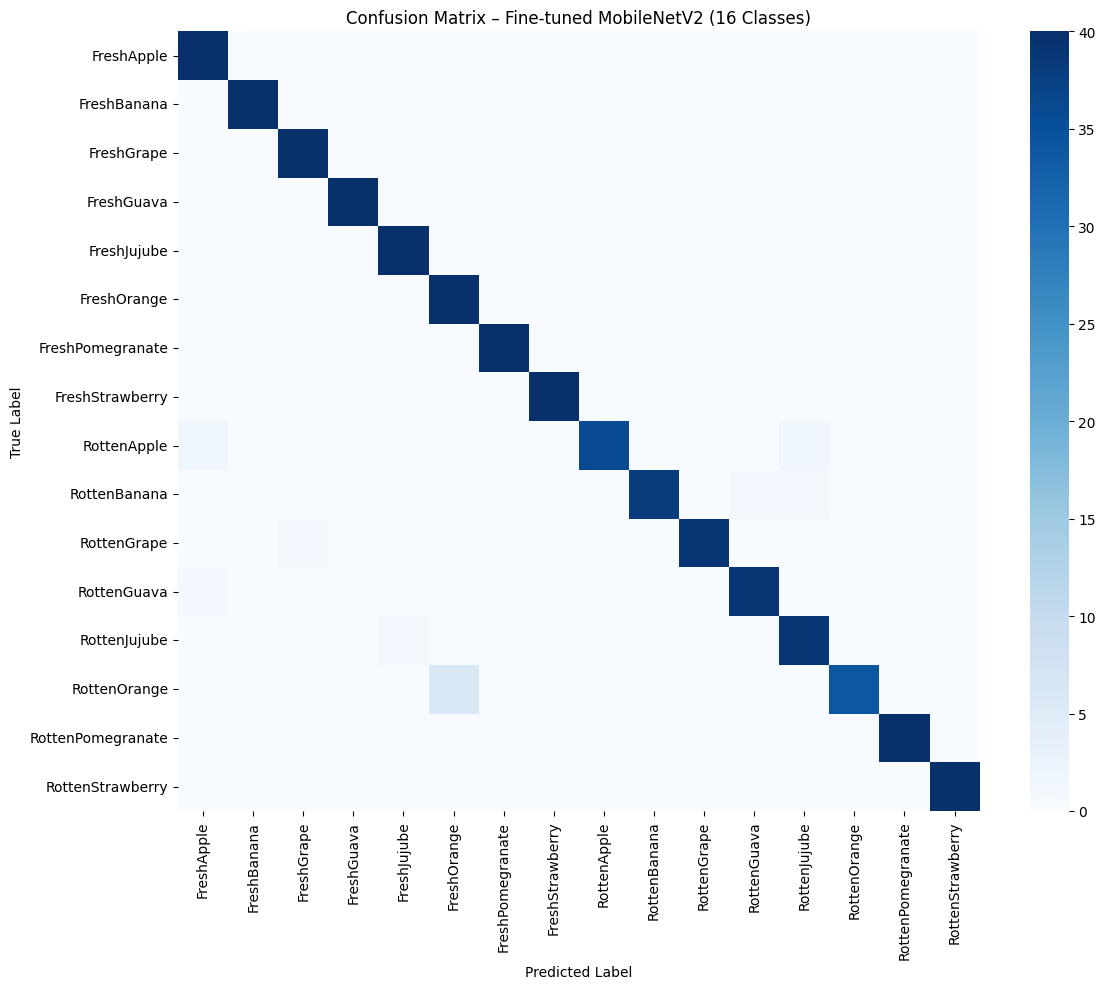

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – Fine-tuned MobileNetV2 (16 Classes)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


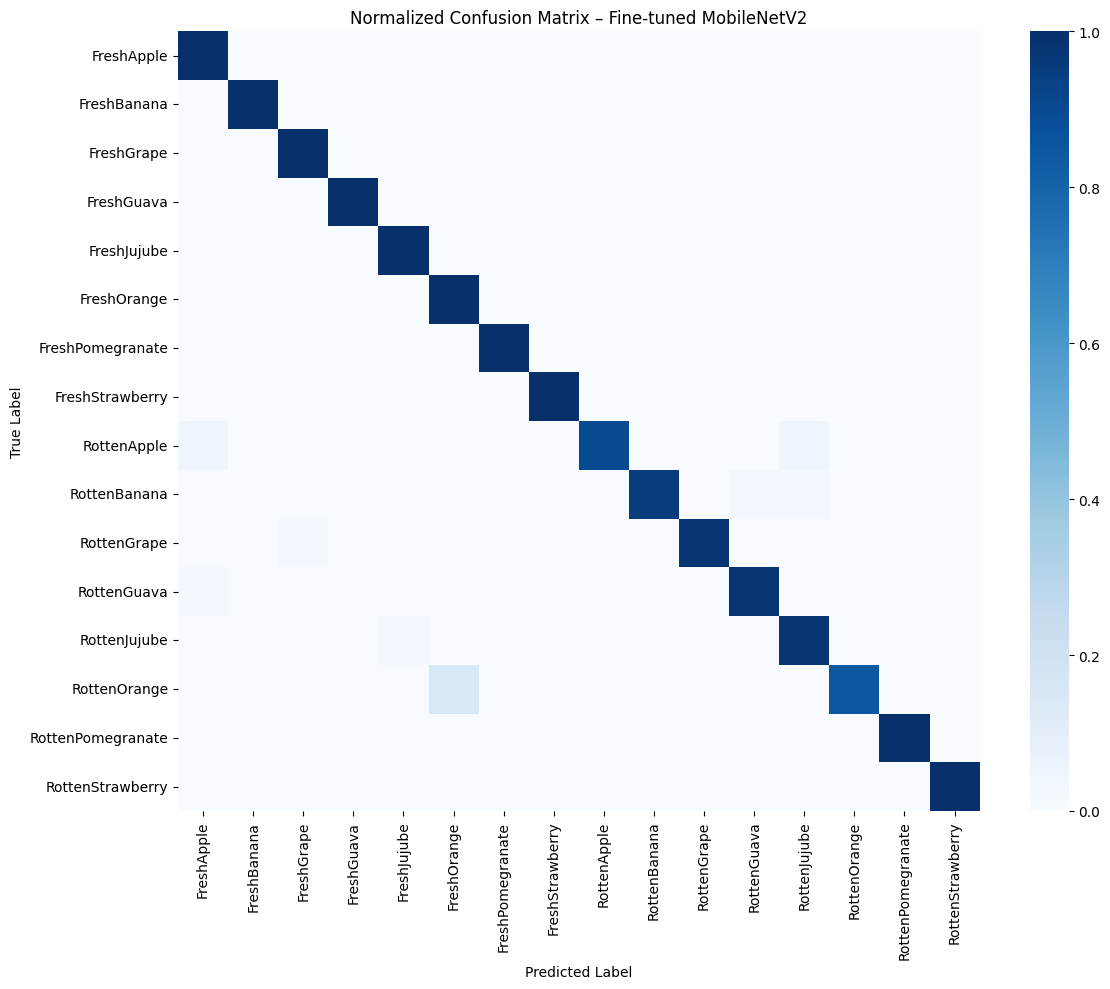

In [ ]:
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_norm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix – Fine-tuned MobileNetV2")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



20/20 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step


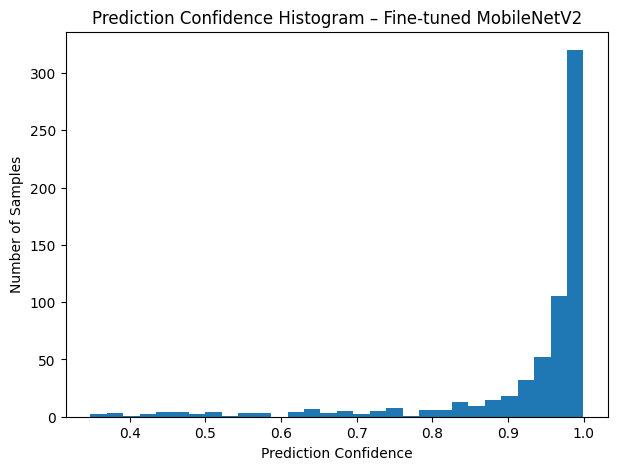

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Predict probabilities
y_pred = model.predict(test_gen)

# Confidence = max softmax probability per sample
confidence_scores = np.max(y_pred, axis=1)

plt.figure(figsize=(7,5))
plt.hist(confidence_scores, bins=30)
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title("Prediction Confidence Histogram – Fine-tuned MobileNetV2")
plt.show()


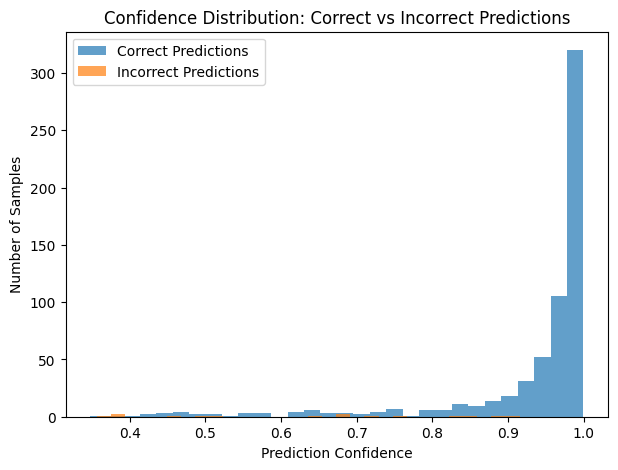

In [ ]:
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes

correct_conf = confidence_scores[y_pred_classes == y_true]
incorrect_conf = confidence_scores[y_pred_classes != y_true]

plt.figure(figsize=(7,5))
plt.hist(correct_conf, bins=30, alpha=0.7, label="Correct Predictions")
plt.hist(incorrect_conf, bins=30, alpha=0.7, label="Incorrect Predictions")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title("Confidence Distribution: Correct vs Incorrect Predictions")
plt.legend()
plt.show()


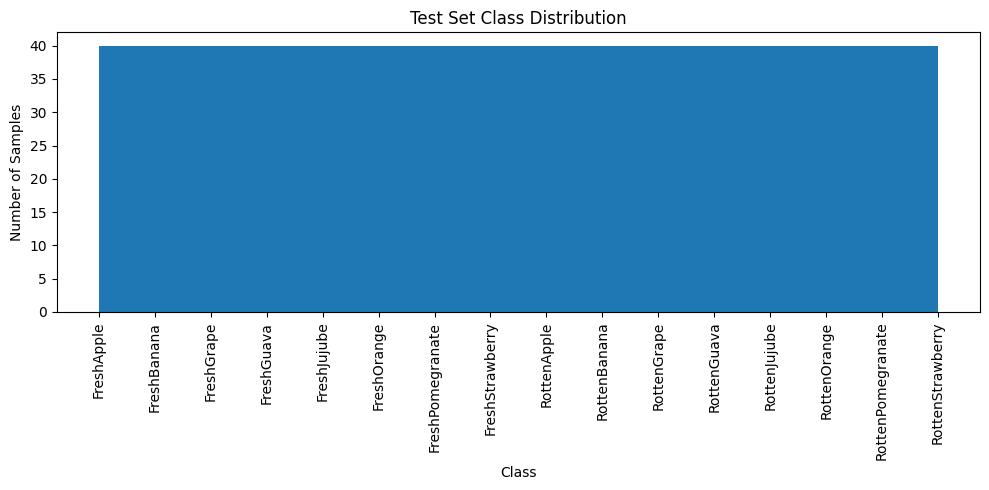

In [ ]:
plt.figure(figsize=(10,5))
plt.hist(y_true, bins=len(class_names))
plt.xticks(range(len(class_names)), class_names, rotation=90)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Test Set Class Distribution")
plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/MobileNetV2_Finetuned_Best.keras"
)


In [ ]:
import tensorflow as tf

test_dir = "/content/drive/MyDrive/Mendeley_16Class_Dataset/test"

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

y_pred = model.predict(test_gen)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

Found 640 images belonging to 16 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


20/20 ━━━━━━━━━━━━━━━━━━━━ 385s 19s/step


In [ ]:
fresh_indices = [i for i, c in enumerate(class_names) if "Fresh" in c]
rotten_indices = [i for i, c in enumerate(class_names) if "Rotten" in c]

p_fresh = np.sum(y_pred[:, fresh_indices], axis=1)
p_rotten = np.sum(y_pred[:, rotten_indices], axis=1)

confidence = np.maximum(p_fresh, p_rotten)


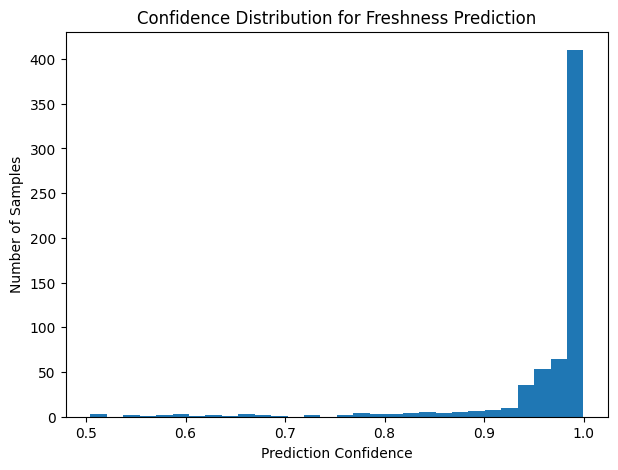

In [ ]:
plt.figure(figsize=(7,5))
plt.hist(confidence, bins=30)
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title("Confidence Distribution for Freshness Prediction")
plt.show()


In [ ]:
high_conf = confidence >= 0.90
mid_conf  = (confidence >= 0.60) & (confidence < 0.90)
low_conf  = confidence < 0.60

print("High confidence samples:", np.sum(high_conf))
print("Mid (transitional) samples:", np.sum(mid_conf))
print("Low confidence samples:", np.sum(low_conf))


High confidence samples: 582
Mid (transitional) samples: 47
Low confidence samples: 11


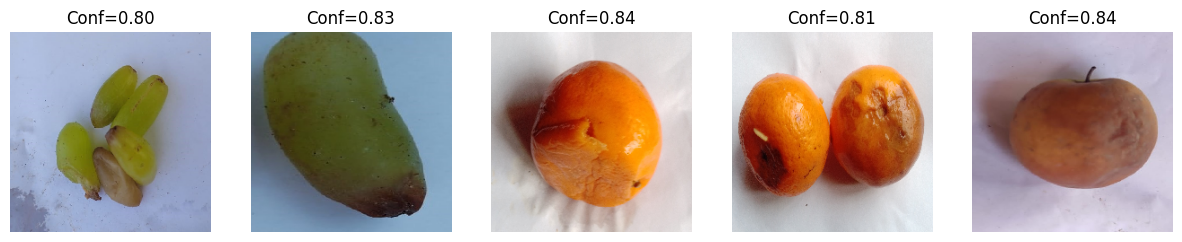

In [ ]:
import random
import math

indices = np.where(mid_conf)[0]
sample_indices = random.sample(list(indices), min(5, len(indices)))

plt.figure(figsize=(15,3))
for i, idx in enumerate(sample_indices):
    # Calculate the batch index and the index within that batch
    batch_idx = math.floor(idx / test_gen.batch_size)
    idx_in_batch = idx % test_gen.batch_size

    # Retrieve the specific batch and then the specific image
    img_batch, _ = test_gen[batch_idx]
    img_to_display = img_batch[idx_in_batch]

    plt.subplot(1,5,i+1)
    plt.imshow(img_to_display)
    plt.axis("off")
    plt.title(f"Conf={confidence[idx]:.2f}")
plt.show()

In [ ]:
feature_extractor = tf.keras.Model(
    inputs=model.input,
    outputs=model.layers[-2].output  # layer before final Dense
)


In [ ]:
features = feature_extractor.predict(test_gen)


20/20 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step


In [ ]:
binary_labels = np.where(p_fresh >= p_rotten, 0, 1)
# 0 = Fresh, 1 = Rotten


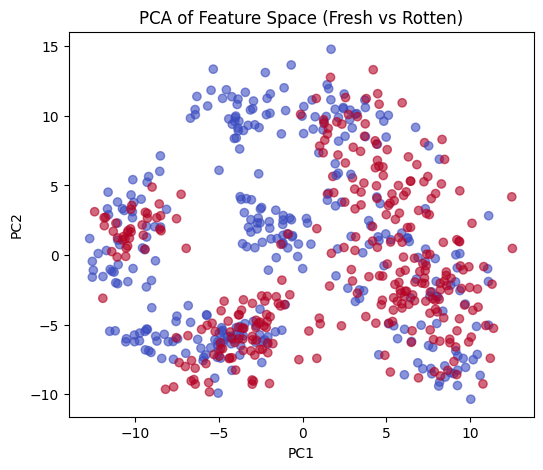

In [ ]:
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features)

plt.figure(figsize=(6,5))
plt.scatter(
    features_pca[:,0],
    features_pca[:,1],
    c=binary_labels,
    cmap="coolwarm",
    alpha=0.6
)
plt.title("PCA of Feature Space (Fresh vs Rotten)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


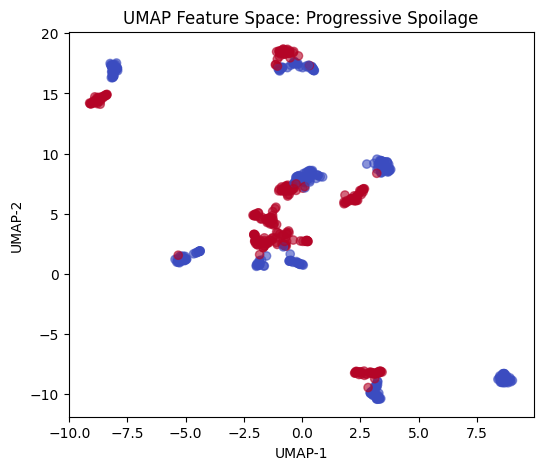

In [ ]:
umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42
)

features_umap = umap_model.fit_transform(features)

plt.figure(figsize=(6,5))
plt.scatter(
    features_umap[:,0],
    features_umap[:,1],
    c=binary_labels,
    cmap="coolwarm",
    alpha=0.6
)
plt.title("UMAP Feature Space: Progressive Spoilage")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.show()


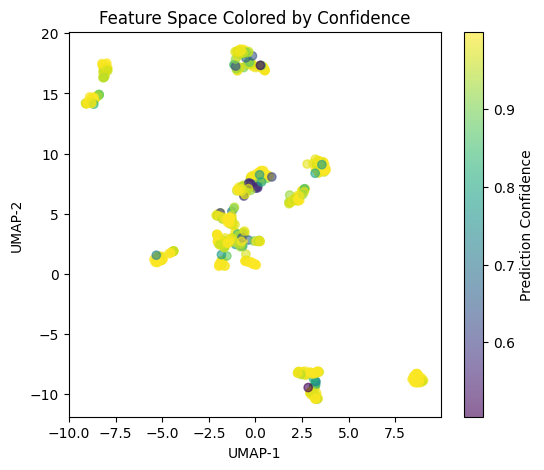

In [ ]:
plt.figure(figsize=(6,5))
plt.scatter(
    features_umap[:,0],
    features_umap[:,1],
    c=confidence,
    cmap="viridis",
    alpha=0.6
)
plt.colorbar(label="Prediction Confidence")
plt.title("Feature Space Colored by Confidence")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.show()
